In [3]:

import pandas as pd
import numpy as np
import os
import time
import joblib

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

import matplotlib.pyplot as plt
import seaborn as sns


In [4]:
PROCESSED_PATH = "../Dataset/processed"

train_df = pd.read_parquet(
    os.path.join(PROCESSED_PATH, "train_baseline.parquet")
)

val_df = pd.read_parquet(
    os.path.join(PROCESSED_PATH, "validation_baseline.parquet")
)

print("Train shape:", train_df.shape)
print("Validation shape:", val_df.shape)

Train shape: (1388907, 66)
Validation shape: (588312, 66)


In [5]:
# Separate features and target

feature_cols = [
    col for col in train_df.columns
    if col != "Target"
]

X_train = train_df[feature_cols]
y_train = train_df["Target"]

X_val = val_df[feature_cols]
y_val = val_df["Target"]

print("Number of Features:", len(feature_cols))

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

Number of Features: 65
X_train: (1388907, 65)
y_train: (1388907,)
X_val: (588312, 65)
y_val: (588312,)


In [6]:

from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=20,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42
)

print(dt_model)


DecisionTreeClassifier(class_weight='balanced', max_depth=20,
                       min_samples_leaf=5, min_samples_split=10,
                       random_state=42)


In [7]:

# Measure training time
start_time = time.time()

dt_model.fit(X_train, y_train)

dt_training_time = time.time() - start_time

print("Decision Tree Training Completed!")
print(f"Training Time: {dt_training_time:.2f} seconds")


Decision Tree Training Completed!
Training Time: 32.08 seconds


In [8]:
# Measure prediction time
start_time = time.time()

y_val_pred = dt_model.predict(X_val)

dt_prediction_time = time.time() - start_time

print("Prediction Completed!")
print(f"Prediction Time: {dt_prediction_time:.2f} seconds")

Prediction Completed!
Prediction Time: 0.14 seconds


In [9]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

dt_accuracy = accuracy_score(y_val, y_val_pred)
dt_precision = precision_score(y_val, y_val_pred)
dt_recall = recall_score(y_val, y_val_pred)
dt_f1 = f1_score(y_val, y_val_pred)

# Probabilities for the positive class (ATTACK)
y_val_proba = dt_model.predict_proba(X_val)[:, 1]

dt_roc_auc = roc_auc_score(y_val, y_val_proba)
dt_pr_auc = average_precision_score(y_val, y_val_proba)

print("Decision Tree - Validation Results")
print("=" * 40)
print(f"Accuracy:  {dt_accuracy:.4f}")
print(f"Precision: {dt_precision:.4f}")
print(f"Recall:    {dt_recall:.4f}")
print(f"F1 Score:  {dt_f1:.4f}")
print(f"ROC-AUC:   {dt_roc_auc:.4f}")
print(f"PR-AUC:    {dt_pr_auc:.4f}")

Decision Tree - Validation Results
Accuracy:  0.9983
Precision: 0.9916
Recall:    0.9992
F1 Score:  0.9954
ROC-AUC:   0.9994
PR-AUC:    0.9967


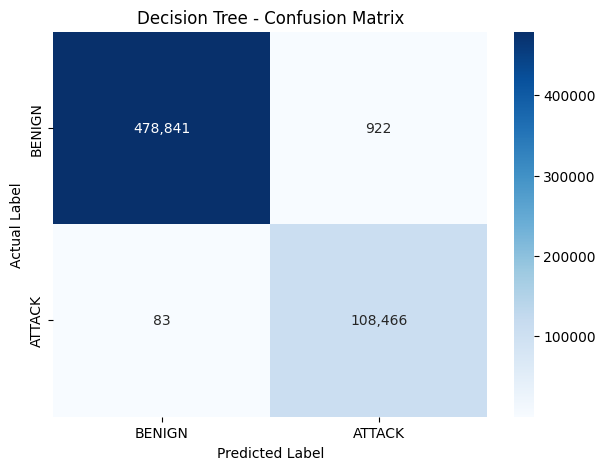

Confusion Matrix:
[[478841    922]
 [    83 108466]]


In [10]:

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

dt_cm = confusion_matrix(y_val, y_val_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    dt_cm,
    annot=True,
    fmt=",",
    cmap="Blues",
    xticklabels=["BENIGN", "ATTACK"],
    yticklabels=["BENIGN", "ATTACK"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Decision Tree - Confusion Matrix")
plt.show()

print("Confusion Matrix:")
print(dt_cm)


In [11]:

feature_importance = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": dt_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 20 Important Features:")
display(feature_importance.head(20))


Top 20 Important Features:


,Feature,Importance
11,Bwd Packet Length Min,0.288646
54,Init_Win_bytes_backward,0.225235
2,Total Fwd Packets,0.217564
0,Destination Port,0.116361
43,PSH Flag Count,0.046191
32,Fwd Header Length,0.021948
6,Fwd Packet Length Max,0.019645
39,Packet Length Std,0.019019
3,Total Backward Packets,0.008314
53,Init_Win_bytes_forward,0.007378


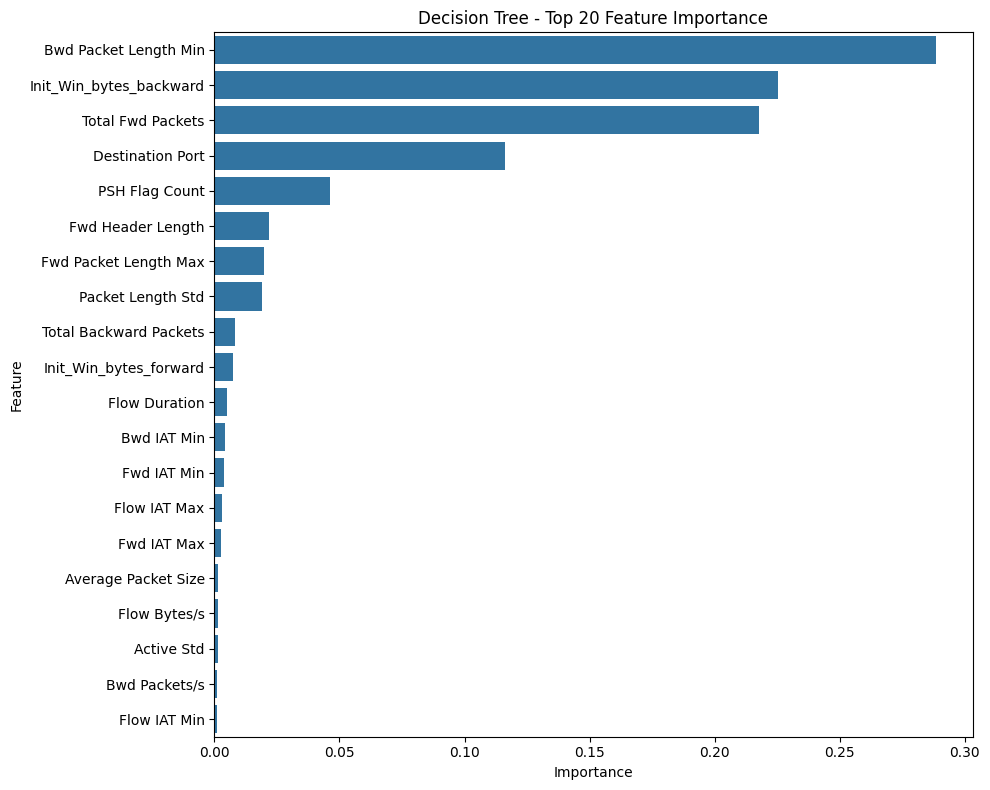

In [12]:
plt.figure(figsize=(10, 8))

sns.barplot(
    data=feature_importance.head(20),
    x="Importance",
    y="Feature"
)

plt.title("Decision Tree - Top 20 Feature Importance")
plt.tight_layout()
plt.show()

In [13]:

from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score

y_train_pred = dt_model.predict(X_train)

train_accuracy = accuracy_score(y_train, y_train_pred)
train_precision = precision_score(y_train, y_train_pred)
train_recall = recall_score(y_train, y_train_pred)
train_f1 = f1_score(y_train, y_train_pred)

print("Decision Tree - Train vs Validation")
print("=" * 50)

print(f"Train Accuracy:      {train_accuracy:.6f}")
print(f"Validation Accuracy: {dt_accuracy:.6f}")

print(f"\nTrain Precision:      {train_precision:.6f}")
print(f"Validation Precision: {dt_precision:.6f}")

print(f"\nTrain Recall:         {train_recall:.6f}")
print(f"Validation Recall:    {dt_recall:.6f}")

print(f"\nTrain F1:             {train_f1:.6f}")
print(f"Validation F1:        {dt_f1:.6f}")


Decision Tree - Train vs Validation
Train Accuracy:      0.998484
Validation Accuracy: 0.998292

Train Precision:      0.992399
Validation Precision: 0.991571

Train Recall:         0.999949
Validation Recall:    0.999235

Train F1:             0.996160
Validation F1:        0.995389


In [14]:

depth_results = []

for depth in [10, 15, 25]:

    model = DecisionTreeClassifier(
        criterion="gini",
        max_depth=depth,
        min_samples_split=10,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42
    )

    start_time = time.time()

    model.fit(X_train, y_train)

    training_time = time.time() - start_time

    start_time = time.time()

    predictions = model.predict(X_val)

    prediction_time = time.time() - start_time

    depth_results.append({
        "Max Depth": depth,
        "F1": f1_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions),
        "Recall": recall_score(y_val, predictions),
        "Training Time": training_time,
        "Prediction Time": prediction_time
    })

depth_results_df = pd.DataFrame(depth_results)

display(depth_results_df)


,Max Depth,F1,Precision,Recall,Training Time,Prediction Time
0,10,0.985538,0.972036,0.999420,27.492736,0.096040
1,15,0.992425,0.985582,0.999364,31.673684,0.105892
2,25,0.997021,0.994918,0.999134,32.594704,0.084466


In [15]:
leaf_results = []

for leaf_size in [1, 5, 10, 20]:

    model = DecisionTreeClassifier(
        criterion="gini",
        max_depth=25,
        min_samples_split=10,
        min_samples_leaf=leaf_size,
        class_weight="balanced",
        random_state=42
    )

    start_time = time.time()

    model.fit(X_train, y_train)

    training_time = time.time() - start_time

    start_time = time.time()

    predictions = model.predict(X_val)

    prediction_time = time.time() - start_time

    leaf_results.append({
        "Min Samples Leaf": leaf_size,
        "F1": f1_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions),
        "Recall": recall_score(y_val, predictions),
        "Training Time": training_time,
        "Prediction Time": prediction_time
    })

leaf_results_df = pd.DataFrame(leaf_results)

display(leaf_results_df)

,Min Samples Leaf,F1,Precision,Recall,Training Time,Prediction Time
0,1,0.997204,0.995683,0.998729,33.936053,0.085751
1,5,0.997021,0.994918,0.999134,32.796227,0.086317
2,10,0.996820,0.994371,0.999281,31.737181,0.082430
3,20,0.996399,0.993678,0.999134,31.993629,0.088298


In [16]:
split_results = []

for split_size in [2, 5, 10, 20, 50]:

    model = DecisionTreeClassifier(
        criterion="gini",
        max_depth=25,
        min_samples_split=split_size,
        min_samples_leaf=1,
        class_weight="balanced",
        random_state=42
    )

    start_time = time.time()

    model.fit(X_train, y_train)

    training_time = time.time() - start_time

    start_time = time.time()

    predictions = model.predict(X_val)

    prediction_time = time.time() - start_time

    split_results.append({
        "Min Samples Split": split_size,
        "F1": f1_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions),
        "Recall": recall_score(y_val, predictions),
        "Training Time": training_time,
        "Prediction Time": prediction_time
    })

split_results_df = pd.DataFrame(split_results)

display(split_results_df)

,Min Samples Split,F1,Precision,Recall,Training Time,Prediction Time
0,2,0.997189,0.996048,0.998333,35.194157,0.108588
1,5,0.997231,0.995902,0.998563,33.282074,0.090631
2,10,0.997204,0.995683,0.998729,32.627164,0.087907
3,20,0.997067,0.995245,0.998895,32.638294,0.086908
4,50,0.996879,0.994680,0.999088,32.252696,0.084138


In [17]:
window_features = [
    col for col in feature_cols
    if "Win_bytes" in col
]

print("TCP Window Features:")
print(window_features)

print("\nNumber of TCP Window Features:")
print(len(window_features))

TCP Window Features:
['Init_Win_bytes_forward', 'Init_Win_bytes_backward']

Number of TCP Window Features:
2


In [18]:
# Experiment A: All Features

dt_all = DecisionTreeClassifier(
    criterion="gini",
    max_depth=25,
    min_samples_split=5,
    min_samples_leaf=1,
    class_weight="balanced",
    random_state=42
)

start_time = time.time()

dt_all.fit(X_train, y_train)

all_training_time = time.time() - start_time

start_time = time.time()

pred_all = dt_all.predict(X_val)

all_prediction_time = time.time() - start_time


# Experiment B: Without TCP Window Features

reduced_features = [
    col for col in feature_cols
    if col not in window_features
]

X_train_reduced = X_train[reduced_features]
X_val_reduced = X_val[reduced_features]

dt_reduced = DecisionTreeClassifier(
    criterion="gini",
    max_depth=25,
    min_samples_split=5,
    min_samples_leaf=1,
    class_weight="balanced",
    random_state=42
)

start_time = time.time()

dt_reduced.fit(X_train_reduced, y_train)

reduced_training_time = time.time() - start_time

start_time = time.time()

pred_reduced = dt_reduced.predict(X_val_reduced)

reduced_prediction_time = time.time() - start_time


# Compare Results

ablation_results = pd.DataFrame([
    {
        "Experiment": "All Features",
        "Number of Features": len(feature_cols),
        "F1": f1_score(y_val, pred_all),
        "Precision": precision_score(y_val, pred_all),
        "Recall": recall_score(y_val, pred_all),
        "Training Time": all_training_time,
        "Prediction Time": all_prediction_time
    },
    {
        "Experiment": "Without TCP Window",
        "Number of Features": len(reduced_features),
        "F1": f1_score(y_val, pred_reduced),
        "Precision": precision_score(y_val, pred_reduced),
        "Recall": recall_score(y_val, pred_reduced),
        "Training Time": reduced_training_time,
        "Prediction Time": reduced_prediction_time
    }
])

display(ablation_results)

,Experiment,Number of Features,F1,Precision,Recall,Training Time,Prediction Time
0,All Features,65,0.997231,0.995902,0.998563,34.401425,0.091446
1,Without TCP Window,63,0.993378,0.990358,0.996416,37.778603,0.092943


In [19]:
window_ablation_results = []

feature_experiments = {
    "All Features": [],
    "Without Forward Window": [
        "Init_Win_bytes_forward"
    ],
    "Without Backward Window": [
        "Init_Win_bytes_backward"
    ],
    "Without Both Windows": window_features
}

for experiment_name, excluded_features in feature_experiments.items():

    selected_features = [
        col for col in feature_cols
        if col not in excluded_features
    ]

    X_train_exp = X_train[selected_features]
    X_val_exp = X_val[selected_features]

    model = DecisionTreeClassifier(
        criterion="gini",
        max_depth=25,
        min_samples_split=5,
        min_samples_leaf=1,
        class_weight="balanced",
        random_state=42
    )

    start_time = time.time()

    model.fit(X_train_exp, y_train)

    training_time = time.time() - start_time

    start_time = time.time()

    predictions = model.predict(X_val_exp)

    prediction_time = time.time() - start_time

    window_ablation_results.append({
        "Experiment": experiment_name,
        "Number of Features": len(selected_features),
        "F1": f1_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions),
        "Recall": recall_score(y_val, predictions),
        "Training Time": training_time,
        "Prediction Time": prediction_time
    })

window_ablation_df = pd.DataFrame(window_ablation_results)

display(window_ablation_df)

,Experiment,Number of Features,F1,Precision,Recall,Training Time,Prediction Time
0,All Features,65,0.997231,0.995902,0.998563,34.416755,0.109147
1,Without Forward Window,64,0.993286,0.990312,0.996278,41.514298,0.097037
2,Without Backward Window,64,0.996951,0.995508,0.998397,38.621314,0.098129
3,Without Both Windows,63,0.993378,0.990358,0.996416,36.516168,0.098050


In [20]:
train_log_df = pd.read_parquet(
    os.path.join(PROCESSED_PATH, "train_log.parquet")
)

val_log_df = pd.read_parquet(
    os.path.join(PROCESSED_PATH, "validation_log.parquet")
)

print("Train Log Shape:", train_log_df.shape)
print("Validation Log Shape:", val_log_df.shape)

Train Log Shape: (1388907, 66)
Validation Log Shape: (588312, 66)


In [21]:
X_train_log = train_log_df[feature_cols]
y_train_log = train_log_df["Target"]

X_val_log = val_log_df[feature_cols]
y_val_log = val_log_df["Target"]

print("X_train_log:", X_train_log.shape)
print("X_val_log:", X_val_log.shape)

X_train_log: (1388907, 65)
X_val_log: (588312, 65)


In [22]:
dt_log = DecisionTreeClassifier(
    criterion="gini",
    max_depth=25,
    min_samples_split=5,
    min_samples_leaf=1,
    class_weight="balanced",
    random_state=42
)

# Training

start_time = time.time()

dt_log.fit(X_train_log, y_train_log)

log_training_time = time.time() - start_time

print("Training Time:", round(log_training_time, 2), "seconds")

Training Time: 35.73 seconds


In [23]:
start_time = time.time()

y_log_pred = dt_log.predict(X_val_log)

log_prediction_time = time.time() - start_time

print("Prediction Time:", round(log_prediction_time, 4), "seconds")

Prediction Time: 0.1735 seconds


In [24]:
log_accuracy = accuracy_score(y_val_log, y_log_pred)

log_precision = precision_score(y_val_log, y_log_pred)

log_recall = recall_score(y_val_log, y_log_pred)

log_f1 = f1_score(y_val_log, y_log_pred)

y_log_proba = dt_log.predict_proba(X_val_log)[:, 1]

log_roc_auc = roc_auc_score(y_val_log, y_log_proba)

log_pr_auc = average_precision_score(y_val_log, y_log_proba)

In [25]:
log_results = pd.DataFrame([{
    "Model": "Decision Tree - Log",
    "Accuracy": log_accuracy,
    "Precision": log_precision,
    "Recall": log_recall,
    "F1": log_f1,
    "ROC-AUC": log_roc_auc,
    "PR-AUC": log_pr_auc,
    "Training Time": log_training_time,
    "Prediction Time": log_prediction_time
}])

display(log_results)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Training Time,Prediction Time
0,Decision Tree - Log,0.998972,0.995875,0.998563,0.997217,0.998925,0.995519,35.732706,0.173518


In [26]:
from sklearn.metrics import confusion_matrix

best_dt = DecisionTreeClassifier(
    criterion="gini",
    max_depth=25,
    min_samples_split=5,
    min_samples_leaf=1,
    class_weight="balanced",
    random_state=42
)

start_time = time.time()

best_dt.fit(X_train, y_train)

best_dt_training_time = time.time() - start_time

best_dt_pred = best_dt.predict(X_val)

best_dt_cm = confusion_matrix(y_val, best_dt_pred)

print("Confusion Matrix:")
print(best_dt_cm)

tn, fp, fn, tp = best_dt_cm.ravel()

print("\nTrue Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

print("\nFalse Positive Rate:", fp / (fp + tn))
print("False Negative Rate:", fn / (fn + tp))

Confusion Matrix:
[[479317    446]
 [   156 108393]]

True Negatives: 479317
False Positives: 446
False Negatives: 156
True Positives: 108393

False Positive Rate: 0.0009296256693409038
False Negative Rate: 0.001437138987922505


In [60]:
os.makedirs("../Models", exist_ok=True)

joblib.dump(
    best_dt,
    "../Models/decision_tree_baseline.pkl"
)

print("Decision Tree model saved successfully!")

Decision Tree model saved successfully!


In [61]:
dt_final_results = pd.DataFrame([{
    "Model": "Decision Tree",
    "Features": len(feature_cols),
    "Max Depth": 25,
    "Min Samples Split": 5,
    "Min Samples Leaf": 1,
    "Accuracy": accuracy_score(y_val, best_dt_pred),
    "Precision": precision_score(y_val, best_dt_pred),
    "Recall": recall_score(y_val, best_dt_pred),
    "F1": f1_score(y_val, best_dt_pred),
    "False Positive Rate": fp / (fp + tn),
    "False Negative Rate": fn / (fn + tp),
    "Training Time": best_dt_training_time
}])

display(dt_final_results)

dt_final_results.to_csv(
    "../Models/decision_tree_results.csv",
    index=False
)

,Model,Features,Max Depth,Min Samples Split,Min Samples Leaf,Accuracy,Precision,Recall,F1,False Positive Rate,False Negative Rate,Training Time
0,Decision Tree,65,25,5,1,0.998977,0.995902,0.998563,0.997231,0.001011,0.001869,35.643145


In [29]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        solver="saga",
        max_iter=100,
        random_state=42
    ))
])

print(lr_model)

Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(class_weight='balanced', random_state=42,
                                    solver='saga'))])


In [30]:
start_time = time.time()

lr_model.fit(X_train, y_train)

lr_training_time = time.time() - start_time

print("Training Time:", round(lr_training_time, 2), "seconds")

Training Time: 127.6 seconds


c:\Users\moham\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [31]:
lr_classifier = lr_model.named_steps["classifier"]

print("Iterations Used:", lr_classifier.n_iter_)
print("Maximum Iterations:", lr_classifier.max_iter)
print("Tolerance:", lr_classifier.tol)

Iterations Used: [100]
Maximum Iterations: 100
Tolerance: 0.0001


In [32]:
lr_model.named_steps["classifier"].set_params(
    max_iter=300,
    tol=1e-3,
    warm_start=True
)

start_time = time.time()

lr_model.fit(X_train, y_train)

lr_training_time = time.time() - start_time

print("Training Time:", round(lr_training_time, 2), "seconds")

print(
    "Iterations Used:",
    lr_model.named_steps["classifier"].n_iter_
)

Training Time: 363.54 seconds
Iterations Used: [300]


c:\Users\moham\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [33]:
lr_classifier = lr_model.named_steps["classifier"]

print("Coefficient Shape:", lr_classifier.coef_.shape)
print("Intercept:", lr_classifier.intercept_)
print("Number of Iterations:", lr_classifier.n_iter_)

Coefficient Shape: (1, 65)
Intercept: [-3.04403656]
Number of Iterations: [300]


In [34]:
from sklearn.linear_model import SGDClassifier

sgd_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SGDClassifier(
        loss="log_loss",
        penalty="l2",
        alpha=0.0001,
        class_weight="balanced",
        max_iter=1000,
        tol=1e-3,
        random_state=42,
        n_jobs=-1
    ))
])

print(sgd_model)

Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 SGDClassifier(class_weight='balanced', loss='log_loss',
                               n_jobs=-1, random_state=42))])


In [35]:
start_time = time.time()

sgd_model.fit(X_train, y_train)

sgd_training_time = time.time() - start_time

print("Training Time:", round(sgd_training_time, 2), "seconds")

sgd_classifier = sgd_model.named_steps["classifier"]

print("Iterations Used:", sgd_classifier.n_iter_)
print("Maximum Iterations:", sgd_classifier.max_iter)

Training Time: 6.44 seconds
Iterations Used: 9
Maximum Iterations: 1000


In [36]:
start_time = time.time()

sgd_pred = sgd_model.predict(X_val)

sgd_prediction_time = time.time() - start_time

sgd_proba = sgd_model.predict_proba(X_val)[:, 1]

sgd_accuracy = accuracy_score(y_val, sgd_pred)
sgd_precision = precision_score(y_val, sgd_pred)
sgd_recall = recall_score(y_val, sgd_pred)
sgd_f1 = f1_score(y_val, sgd_pred)

sgd_roc_auc = roc_auc_score(y_val, sgd_proba)
sgd_pr_auc = average_precision_score(y_val, sgd_proba)

sgd_cm = confusion_matrix(y_val, sgd_pred)

print("SGDClassifier - Validation Results")
print("=" * 45)

print("Accuracy:", sgd_accuracy)
print("Precision:", sgd_precision)
print("Recall:", sgd_recall)
print("F1 Score:", sgd_f1)
print("ROC-AUC:", sgd_roc_auc)
print("PR-AUC:", sgd_pr_auc)

print("\nConfusion Matrix:")
print(sgd_cm)

print("\nPrediction Time:", round(sgd_prediction_time, 2), "seconds")

SGDClassifier - Validation Results
Accuracy: 0.9338191299854499
Precision: 0.7555767677509362
Recall: 0.9479774111230873
F1 Score: 0.8409121553981997
ROC-AUC: 0.981301984429047
PR-AUC: 0.925569819739338

Confusion Matrix:
[[446475  33288]
 [  5647 102902]]

Prediction Time: 0.24 seconds


In [37]:
from sklearn.metrics import precision_recall_curve

precisions, recalls, thresholds = precision_recall_curve(
    y_val,
    sgd_proba
)

f1_scores = (
    2 * precisions[:-1] * recalls[:-1]
    / (precisions[:-1] + recalls[:-1] + 1e-10)
)

best_idx = np.argmax(f1_scores)

print("Best Threshold:", thresholds[best_idx])
print("Best Precision:", precisions[best_idx])
print("Best Recall:", recalls[best_idx])
print("Best F1:", f1_scores[best_idx])

Best Threshold: 0.5619124428505317
Best Precision: 0.7840793863349614
Best Recall: 0.9331822494910132
Best F1: 0.8521578194170211


In [38]:
# Apply the selected threshold
best_threshold = thresholds[best_idx]

sgd_pred_tuned = (sgd_proba >= best_threshold).astype(int)

# Confusion Matrix
cm_tuned = confusion_matrix(y_val, sgd_pred_tuned)

tn, fp, fn, tp = cm_tuned.ravel()

# Metrics
tuned_precision = precision_score(y_val, sgd_pred_tuned)
tuned_recall = recall_score(y_val, sgd_pred_tuned)
tuned_f1 = f1_score(y_val, sgd_pred_tuned)

fpr = fp / (fp + tn)
fnr = fn / (fn + tp)

print("Selected Threshold:", best_threshold)
print("Precision:", tuned_precision)
print("Recall:", tuned_recall)
print("F1 Score:", tuned_f1)

print("\nConfusion Matrix:")
print(cm_tuned)

print("\nFalse Positive Rate:", fpr)
print("False Negative Rate:", fnr)

Selected Threshold: 0.5619124428505317
Precision: 0.7840793863349614
Recall: 0.9331822494910132
F1 Score: 0.8521578194666443

Confusion Matrix:
[[451868  27895]
 [  7253 101296]]

False Positive Rate: 0.05814329158355271
False Negative Rate: 0.06681775050898672


In [39]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=25,
    min_samples_split=5,
    min_samples_leaf=1,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

print(rf_model)

RandomForestClassifier(class_weight='balanced', max_depth=25,
                       min_samples_split=5, n_jobs=-1, random_state=42)


In [40]:
start_time = time.time()

rf_model.fit(X_train, y_train)

rf_training_time = time.time() - start_time

print("Training Time:", round(rf_training_time, 2), "seconds")
print("Number of Trees:", len(rf_model.estimators_))
print("Maximum Depth:", rf_model.max_depth)

Training Time: 73.82 seconds
Number of Trees: 100
Maximum Depth: 25


In [41]:
# Prediction
start_time = time.time()

rf_pred = rf_model.predict(X_val)

rf_prediction_time = time.time() - start_time

# Probabilities
rf_proba = rf_model.predict_proba(X_val)[:, 1]

# Metrics
rf_accuracy = accuracy_score(y_val, rf_pred)
rf_precision = precision_score(y_val, rf_pred)
rf_recall = recall_score(y_val, rf_pred)
rf_f1 = f1_score(y_val, rf_pred)

rf_roc_auc = roc_auc_score(y_val, rf_proba)
rf_pr_auc = average_precision_score(y_val, rf_proba)

rf_cm = confusion_matrix(y_val, rf_pred)

print("Random Forest - Validation Results")
print("=" * 45)

print("Accuracy:", rf_accuracy)
print("Precision:", rf_precision)
print("Recall:", rf_recall)
print("F1 Score:", rf_f1)
print("ROC-AUC:", rf_roc_auc)
print("PR-AUC:", rf_pr_auc)

print("\nConfusion Matrix:")
print(rf_cm)

print("\nPrediction Time:", round(rf_prediction_time, 2), "seconds")

Random Forest - Validation Results
Accuracy: 0.9990345258978229
Precision: 0.9957941908408864
Recall: 0.9989866327649264
F1 Score: 0.9973878572151247
ROC-AUC: 0.9999586199253242
PR-AUC: 0.9998100112389142

Confusion Matrix:
[[479305    458]
 [   110 108439]]

Prediction Time: 0.63 seconds


In [42]:
rf_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

rf_importance = rf_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 15 Random Forest Features:")
print(rf_importance.head(15).to_string(index=False))

Top 15 Random Forest Features:
                Feature  Importance
       Destination Port    0.080423
    Average Packet Size    0.074617
 Init_Win_bytes_forward    0.049007
 Packet Length Variance    0.045946
      Subflow Fwd Bytes    0.039911
  Bwd Packet Length Std    0.039644
      Packet Length Std    0.038933
Init_Win_bytes_backward    0.038280
  Bwd Packet Length Min    0.037858
      Min Packet Length    0.037137
 Bwd Packet Length Mean    0.036199
     Packet Length Mean    0.035948
 Fwd Packet Length Mean    0.032988
  Fwd Packet Length Min    0.027693
  Fwd Packet Length Max    0.026568


In [43]:
rf_tree_results = []

for n_trees in [25, 50, 75]:

    model = RandomForestClassifier(
        n_estimators=n_trees,
        max_depth=25,
        min_samples_split=5,
        min_samples_leaf=1,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    start_time = time.time()
    model.fit(X_train, y_train)
    training_time = time.time() - start_time

    start_time = time.time()
    predictions = model.predict(X_val)
    prediction_time = time.time() - start_time

    precision = precision_score(y_val, predictions)
    recall = recall_score(y_val, predictions)
    f1 = f1_score(y_val, predictions)

    rf_tree_results.append({
        "Trees": n_trees,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "Training Time": training_time,
        "Prediction Time": prediction_time
    })

    print(f"Finished {n_trees} Trees")

Finished 25 Trees
Finished 50 Trees
Finished 75 Trees


In [44]:
rf_tree_results_df = pd.DataFrame(rf_tree_results)

print(
    rf_tree_results_df.to_string(index=False)
)

 Trees  Precision   Recall       F1  Training Time  Prediction Time
    25   0.995701 0.998544 0.997121      20.567829         0.219368
    50   0.995776 0.998959 0.997365      41.916649         0.419702
    75   0.995812 0.998959 0.997383      62.309618         0.456275


In [45]:
rf_depth_results = []

for depth in [10, 15, 20, 25, 30]:

    model = RandomForestClassifier(
        n_estimators=50,
        max_depth=depth,
        min_samples_split=5,
        min_samples_leaf=1,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    start_time = time.time()
    model.fit(X_train, y_train)
    training_time = time.time() - start_time

    start_time = time.time()
    predictions = model.predict(X_val)
    prediction_time = time.time() - start_time

    rf_depth_results.append({
        "Max Depth": depth,
        "Precision": precision_score(y_val, predictions),
        "Recall": recall_score(y_val, predictions),
        "F1": f1_score(y_val, predictions),
        "Training Time": training_time,
        "Prediction Time": prediction_time
    })

    print(f"Finished Depth: {depth}")

Finished Depth: 10
Finished Depth: 15
Finished Depth: 20
Finished Depth: 25
Finished Depth: 30


In [46]:
rf_depth_results_df = pd.DataFrame(rf_depth_results)

print(rf_depth_results_df.to_string(index=False))

 Max Depth  Precision   Recall       F1  Training Time  Prediction Time
        10   0.983438 0.995587 0.989475      33.975837         0.299560
        15   0.993763 0.998130 0.995942      37.280564         0.333919
        20   0.995156 0.999199 0.997173      39.735863         0.331705
        25   0.995776 0.998959 0.997365      39.885346         0.350251
        30   0.995945 0.997909 0.996926      39.878285         0.341784


In [47]:
rf_leaf_results = []

for leaf in [1, 2, 5, 10, 20]:

    model = RandomForestClassifier(
        n_estimators=50,
        max_depth=25,
        min_samples_split=5,
        min_samples_leaf=leaf,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    start_time = time.time()

    model.fit(X_train, y_train)

    training_time = time.time() - start_time

    start_time = time.time()

    predictions = model.predict(X_val)

    prediction_time = time.time() - start_time

    rf_leaf_results.append({
        "Min Samples Leaf": leaf,
        "Precision": precision_score(y_val, predictions),
        "Recall": recall_score(y_val, predictions),
        "F1": f1_score(y_val, predictions),
        "Training Time": training_time,
        "Prediction Time": prediction_time
    })

    print(f"Finished Leaf: {leaf}")


rf_leaf_results_df = pd.DataFrame(rf_leaf_results)

print(rf_leaf_results_df.to_string(index=False))

Finished Leaf: 1
Finished Leaf: 2
Finished Leaf: 5
Finished Leaf: 10
Finished Leaf: 20
 Min Samples Leaf  Precision   Recall       F1  Training Time  Prediction Time
                1   0.995776 0.998959 0.997365      40.607368         0.329482
                2   0.995710 0.998627 0.997167      38.492891         0.336334
                5   0.995383 0.998913 0.997145      40.241107         0.352024
               10   0.994789 0.998885 0.996833      38.412394         0.328401
               20   0.994478 0.998719 0.996594      38.406739         0.339779


In [48]:
RandomForestClassifier(
    n_estimators=50,
    max_depth=25,
    min_samples_split=5,
    min_samples_leaf=1,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",50
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",25
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_featu

In [49]:
[name for name in globals() if "rf" in name.lower() and "result" in name.lower()]

['rf_tree_results',
 'rf_tree_results_df',
 'rf_depth_results',
 'rf_depth_results_df',
 'rf_leaf_results',
 'rf_leaf_results_df']

In [50]:
rf_experiments = pd.concat([
    rf_tree_results_df.assign(Experiment="Number of Trees"),
    rf_depth_results_df.assign(Experiment="Max Depth"),
    rf_leaf_results_df.assign(Experiment="Min Samples Leaf")
], ignore_index=True)

rf_experiments.to_csv(
    "../models/random_forest_experiments.csv",
    index=False
)

print("Saved Random Forest experiments!")
print(rf_experiments.shape)
print(rf_experiments)

Saved Random Forest experiments!
(13, 9)
    Trees  Precision    Recall        F1  Training Time  Prediction Time  \
0    25.0   0.995701  0.998544  0.997121      20.567829         0.219368   
1    50.0   0.995776  0.998959  0.997365      41.916649         0.419702   
2    75.0   0.995812  0.998959  0.997383      62.309618         0.456275   
3     NaN   0.983438  0.995587  0.989475      33.975837         0.299560   
4     NaN   0.993763  0.998130  0.995942      37.280564         0.333919   
5     NaN   0.995156  0.999199  0.997173      39.735863         0.331705   
6     NaN   0.995776  0.998959  0.997365      39.885346         0.350251   
7     NaN   0.995945  0.997909  0.996926      39.878285         0.341784   
8     NaN   0.995776  0.998959  0.997365      40.607368         0.329482   
9     NaN   0.995710  0.998627  0.997167      38.492891         0.336334   
10    NaN   0.995383  0.998913  0.997145      40.241107         0.352024   
11    NaN   0.994789  0.998885  0.996833      3

In [51]:
rf_experiments["Parameter Value"] = (
    rf_experiments["Trees"]
    .fillna(rf_experiments["Max Depth"])
    .fillna(rf_experiments["Min Samples Leaf"])
)

rf_experiments["Parameter"] = rf_experiments["Experiment"]

rf_experiments = rf_experiments[
    [
        "Parameter",
        "Parameter Value",
        "Precision",
        "Recall",
        "F1",
        "Training Time",
        "Prediction Time"
    ]
]

rf_experiments.to_csv(
    "../models/random_forest_experiments.csv",
    index=False
)

print(rf_experiments.to_string(index=False))

       Parameter  Parameter Value  Precision   Recall       F1  Training Time  Prediction Time
 Number of Trees             25.0   0.995701 0.998544 0.997121      20.567829         0.219368
 Number of Trees             50.0   0.995776 0.998959 0.997365      41.916649         0.419702
 Number of Trees             75.0   0.995812 0.998959 0.997383      62.309618         0.456275
       Max Depth             10.0   0.983438 0.995587 0.989475      33.975837         0.299560
       Max Depth             15.0   0.993763 0.998130 0.995942      37.280564         0.333919
       Max Depth             20.0   0.995156 0.999199 0.997173      39.735863         0.331705
       Max Depth             25.0   0.995776 0.998959 0.997365      39.885346         0.350251
       Max Depth             30.0   0.995945 0.997909 0.996926      39.878285         0.341784
Min Samples Leaf              1.0   0.995776 0.998959 0.997365      40.607368         0.329482
Min Samples Leaf              2.0   0.995710 0.998

In [52]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

models = {
    "Decision Tree": DecisionTreeClassifier(
        criterion="gini",
        max_depth=25,
        min_samples_split=5,
        min_samples_leaf=1,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=50,
        max_depth=25,
        min_samples_split=5,
        min_samples_leaf=1,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

comparison_results = []

for name, model in models.items():

    start = time.time()
    model.fit(X_train, y_train)
    training_time = time.time() - start

    start = time.time()
    predictions = model.predict(X_val)
    prediction_time = time.time() - start

    probabilities = model.predict_proba(X_val)[:, 1]

    comparison_results.append({
        "Model": name,
        "Precision": precision_score(y_val, predictions),
        "Recall": recall_score(y_val, predictions),
        "F1": f1_score(y_val, predictions),
        "ROC-AUC": roc_auc_score(y_val, probabilities),
        "PR-AUC": average_precision_score(y_val, probabilities),
        "Training Time": training_time,
        "Prediction Time": prediction_time
    })

comparison_df = pd.DataFrame(comparison_results)

print(comparison_df.to_string(index=False))

        Model  Precision   Recall       F1  ROC-AUC   PR-AUC  Training Time  Prediction Time
Decision Tree   0.995902 0.998563 0.997231 0.998920 0.995513      35.126868         0.119137
Random Forest   0.995776 0.998959 0.997365 0.999957 0.999798      39.250233         0.325543


In [53]:
import os
import joblib

os.makedirs("../models", exist_ok=True)

model_sizes = []

for name, model in models.items():

    filename = name.lower().replace(" ", "_") + ".pkl"
    filepath = os.path.join("../models", filename)

    joblib.dump(model, filepath)

    size_mb = os.path.getsize(filepath) / (1024 ** 2)

    model_sizes.append({
        "Model": name,
        "Size (MB)": size_mb
    })

model_sizes_df = pd.DataFrame(model_sizes)

print(model_sizes_df.to_string(index=False))

        Model  Size (MB)
Decision Tree   0.207482
Random Forest  22.455590


In [54]:
from sklearn.metrics import confusion_matrix

for name, model in models.items():

    predictions = model.predict(X_val)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        predictions
    ).ravel()

    print(f"\n{name}")
    print("-" * 35)

    print(f"True Negatives: {tn:,}")
    print(f"False Positives: {fp:,}")
    print(f"False Negatives: {fn:,}")
    print(f"True Positives: {tp:,}")

    print(f"False Positive Rate: {fp / (fp + tn):.6%}")
    print(f"False Negative Rate: {fn / (fn + tp):.6%}")


Decision Tree
-----------------------------------
True Negatives: 479,317
False Positives: 446
False Negatives: 156
True Positives: 108,393
False Positive Rate: 0.092963%
False Negative Rate: 0.143714%

Random Forest
-----------------------------------
True Negatives: 479,303
False Positives: 460
False Negatives: 113
True Positives: 108,436
False Positive Rate: 0.095881%
False Negative Rate: 0.104100%


In [55]:
test_df = pd.read_parquet(
    os.path.join(PROCESSED_PATH, "test_baseline.parquet")
)

X_test = test_df[feature_cols]
y_test = test_df["Target"]

print("Test Shape:", X_test.shape)

print("\nTarget Distribution:")
print(y_test.value_counts())

print("\nTarget Percentage:")
print(y_test.value_counts(normalize=True) * 100)

Test Shape: (853524, 65)

Target Distribution:
Target
0    677463
1    176061
Name: count, dtype: int64

Target Percentage:
Target
0    79.372461
1    20.627539
Name: proportion, dtype: float64


In [56]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

final_results = []

for name, model in models.items():

    start_time = time.time()

    predictions = model.predict(X_test)

    prediction_time = time.time() - start_time

    probabilities = model.predict_proba(X_test)[:, 1]

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions
    ).ravel()

    final_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "PR-AUC": average_precision_score(y_test, probabilities),
        "False Positives": fp,
        "False Negatives": fn,
        "FPR": fp / (fp + tn),
        "FNR": fn / (fn + tp),
        "Prediction Time": prediction_time
    })

final_results_df = pd.DataFrame(final_results)

print(final_results_df.to_string(index=False))

        Model  Accuracy  Precision   Recall       F1  ROC-AUC   PR-AUC  False Positives  False Negatives      FPR      FNR  Prediction Time
Decision Tree  0.998931   0.996249 0.998580 0.997413 0.998906 0.995829              662              250 0.000977 0.001420         0.143254
Random Forest  0.998812   0.996117 0.998131 0.997123 0.999892 0.999563              685              329 0.001011 0.001869         0.514756


In [57]:
import joblib
import os

os.makedirs("../Models", exist_ok=True)

final_model = models["Decision Tree"]

joblib.dump(
    final_model,
    "../Models/sentinelai_final_model.pkl"
)

print("SentinelAI Final Model Saved!")

print(
    "Model Size:",
    round(
        os.path.getsize(
            "../models/sentinelai_final_model.pkl"
        ) / (1024 ** 2),
        4
    ),
    "MB"
)

SentinelAI Final Model Saved!
Model Size: 0.2075 MB


In [58]:
import os

print("Model exists:",
      os.path.exists("../Models/sentinelai_final_model.pkl"))

print("Imputer exists:",
      os.path.exists("../Models/median_imputer.pkl"))

Model exists: True
Imputer exists: True


In [59]:
import joblib
import os

# Save the exact feature order used during training
feature_columns = X_train.columns.tolist()

joblib.dump(
    feature_columns,
    "../models/feature_columns.pkl"
)

print("Feature columns saved successfully!")
print("Number of features:", len(feature_columns))
print("First 10 features:")
print(feature_columns[:10])

Feature columns saved successfully!
Number of features: 65
First 10 features:
['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std']


In [62]:
import joblib
import pandas as pd
import os

MODEL_PATH = "../models"

# Load saved artifacts
model = joblib.load(
    os.path.join(MODEL_PATH, "sentinelai_final_model.pkl")
)

imputer = joblib.load(
    os.path.join(MODEL_PATH, "median_imputer.pkl")
)

feature_columns = joblib.load(
    os.path.join(MODEL_PATH, "feature_columns.pkl")
)

print("Model:", type(model).__name__)
print("Imputer:", type(imputer).__name__)
print("Number of features:", len(feature_columns))

print("Model expects:", model.n_features_in_)
print("Imputer expects:", imputer.n_features_in_)

Model: DecisionTreeClassifier
Imputer: SimpleImputer
Number of features: 65
Model expects: 65
Imputer expects: 65


In [65]:
# Take a small sample
sample = X_test.iloc[:10].copy()

# Ensure exact feature order
sample = sample[feature_columns]

# Apply the saved imputer and preserve feature names
sample_imputed = pd.DataFrame(
    imputer.transform(sample),
    columns=feature_columns,
    index=sample.index
)

# Predict
predictions = model.predict(sample_imputed)

# Compare with actual labels
results = pd.DataFrame({
    "Actual": y_test.iloc[:10].values,
    "Predicted": predictions
})

# Convert labels to readable names
results["Actual"] = results["Actual"].map({
    0: "BENIGN",
    1: "ATTACK"
})

results["Predicted"] = results["Predicted"].map({
    0: "BENIGN",
    1: "ATTACK"
})

print(results)

   Actual Predicted
0  BENIGN    BENIGN
1  BENIGN    BENIGN
2  BENIGN    BENIGN
3  BENIGN    BENIGN
4  BENIGN    BENIGN
5  BENIGN    BENIGN
6  BENIGN    BENIGN
7  BENIGN    BENIGN
8  BENIGN    BENIGN
9  BENIGN    BENIGN


In [66]:
# Select 10 attack samples
attack_sample = X_test[y_test == 1].iloc[:10].copy()

# Preserve feature order
attack_sample = attack_sample[feature_columns]

# Apply saved imputer
attack_imputed = pd.DataFrame(
    imputer.transform(attack_sample),
    columns=feature_columns,
    index=attack_sample.index
)

# Predict
attack_predictions = model.predict(attack_imputed)

# Display results
attack_results = pd.DataFrame({
    "Actual": y_test.loc[attack_sample.index].values,
    "Predicted": attack_predictions
})

attack_results["Actual"] = attack_results["Actual"].map({
    0: "BENIGN",
    1: "ATTACK"
})

attack_results["Predicted"] = attack_results["Predicted"].map({
    0: "BENIGN",
    1: "ATTACK"
})

print(attack_results)

   Actual Predicted
0  ATTACK    ATTACK
1  ATTACK    ATTACK
2  ATTACK    ATTACK
3  ATTACK    ATTACK
4  ATTACK    ATTACK
5  ATTACK    ATTACK
6  ATTACK    ATTACK
7  ATTACK    ATTACK
8  ATTACK    ATTACK
9  ATTACK    ATTACK


In [67]:
def predict_network_traffic(input_data):

    # Ensure DataFrame format
    if not isinstance(input_data, pd.DataFrame):
        input_data = pd.DataFrame(input_data)

    # Validate required features
    missing_features = set(feature_columns) - set(input_data.columns)

    if missing_features:
        raise ValueError(
            f"Missing features: {sorted(missing_features)}"
        )

    # Keep exact training feature order
    input_data = input_data[feature_columns]

    # Apply saved imputer
    input_imputed = pd.DataFrame(
        imputer.transform(input_data),
        columns=feature_columns,
        index=input_data.index
    )

    # Predict
    predictions = model.predict(input_imputed)

    # Convert predictions to readable labels
    labels = {
        0: "BENIGN",
        1: "ATTACK"
    }

    return [labels[prediction] for prediction in predictions]


In [68]:
test_sample = X_test.iloc[:5].copy()

print(predict_network_traffic(test_sample))

['BENIGN', 'BENIGN', 'BENIGN', 'BENIGN', 'BENIGN']
